In [59]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import gamma

### Initial parameters and functions from QCD theory ###

In [60]:
uv_p0 = np.array([2.27296347428, -0.5, 3.3, 0]) #Initial u_v parameters
ub_p0 = np.array([0.13, -1.266, 5.6, 0]) #Initial \bar{u} parameters
dv_p0 = np.array([1.13648173714, -0.5, 3.3, 0]) #Initial d_v parameters
db_p0 = np.array([0.13, -1.266, 5.6, 0]) #Initial \bar{d} parameters
kappa = 0.5 #"Strange quark scaling factor" 

initParams = np.array([uv_p0, ub_p0, dv_p0, db_p0], dtype=np.float64) #Store initial parameters as array (for convenience)
numParams = len(uv_p0) #Number of parameters per PDF
numFixedParams = len(initParams[:,0]) #Number of fixed parameters (i.e. all of the a0 parameters)
numFreeParams = initParams.size - numFixedParams #Number of free parameters to be fitted
initParams1D = initParams.flatten() #Store the initial parametes as a 1D flattened array

#Parametrized PDF functional form
def f(x, params):
    return params[0]*x**(params[1]) * (1-x)**(params[2]) * (1 + (params[3])*np.sqrt(x))

#F2 structure function (takes in a 2D array of parameters)
def F2(x, paramsMatrix):
    uv_params = paramsMatrix[0]
    ub_params = paramsMatrix[1]
    dv_params = paramsMatrix[2]
    db_params = paramsMatrix[3]
    return x*((4/9)*(f(x, uv_params) + 2*f(x, ub_params)) +
              (1/9)*(f(x, dv_params) + 2*f(x, db_params)) +
              (1/9)*kappa*(f(x, ub_params)+f(x, db_params))
              )

#F2 Structure function (takes in a flattened 1D array of parameters)
def F21D(x, params):
    uv_params = params[0:numParams]
    ub_params = params[4:2*numParams]
    dv_params = params[8:3*numParams]
    db_params = params[12:4*numParams]
    return x*((4/9)*(f(x, uv_params) + 2*f(x, ub_params)) +
              (1/9)*(f(x, dv_params) + 2*f(x, db_params)) +
              (1/9)*kappa*(f(x, ub_params)+f(x, db_params))
              )

### Algorithms ####

Finite difference perturbation

In [61]:
#Input: parameters (1D or 2D), index of parameter to perturb, perturbation size
#Optional: Column index of parameter if inputting a 2D array, Boolean for whether or not to calculate a second perturbation
def perturb(params, i, h, j=None, step2 = False):
    if len(params.shape) == 1:
        pplus = np.copy(params)
        pplus[i] += h
        pminus = np.copy(params)
        pminus[i] -= h
        if step2: #Second perturbation is used for 5-point stencil finite difference
            p2plus = np.copy(params)
            p2plus[i] += 2*h
            p2minus = np.copy(params)
            p2minus[i] -= 2*h

    if len(params.shape) == 2:
        pplus = np.copy(params)
        pplus[i,j] += h
        pminus = np.copy(params)
        pminus[i,j] -= h
        if step2:
            p2plus = np.copy(params)
            p2plus[i,j] += 2*h
            p2minus = np.copy(params)
            p2minus[i,j] -= 2*h
    
    if step2:
        return pplus, pminus, p2plus, p2minus
    else:
        return pplus, pminus

Jacobian matrix via finite-difference approximation

In [62]:
#Input: residual vector, 1D array of parameters, list of fixed parameters
def Jacobian(rvec, params, fixedParams=[]):
    dims = len(params.flatten()) - len(fixedParams)
    J = np.zeros((len(rvec(params)), dims))
    h = (np.finfo(np.float64).eps)**(1/3) #Optimal step size for central difference

    fixedIndices = []
    for fix in fixedParams:
        fixedIndices.append(np.ravel_multi_index(fix[0], (numFixedParams, numParams)))

    index = np.arange(0,len(initParams1D))
    index = index[~np.isin(index, fixedIndices)] #Find all of the indices corresponding to free parameters

    #Calculate the 5-point stencil approximation of the first-derivative, ignoring fixed parameters
    for j in range(dims):
        pplus, pminus, p2plus, p2minus = perturb(params, index[j], h, step2=True)
        try:
            J[:,j] = (-rvec(p2plus) + 8*rvec(pplus) - 8*rvec(pminus) + rvec(p2minus)) / (12*h)
        except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
            pass

    return J

Hessian matrix via finite-difference approximation

In [63]:
#Input: Function to calculate the Hessian of, x-value to evaluate at, 1D array of parameters to evaluate at,
#       list of fixed parameters
def hessian(func, x, params, fixedParams=[]):
    dims = len(params.flatten()) - len(fixedParams)
    H = np.zeros((dims, dims))
    h = (np.finfo(np.float64).eps)**(1/4) * 1e-9 #Optimal step size for second partial central difference

    fixedIndices = []
    for fix in fixedParams:
        fixedIndices.append(np.ravel_multi_index(fix[0], (numFixedParams, numParams)))

    index = np.arange(0,len(initParams1D))
    index = index[~np.isin(index, fixedIndices)] #Find all of the indices corresponding to free parameters

    #Calculate the 4-point stencil approximation of the second partial derivatives, ignoring fixed parameters
    for i in range(dims):
        for j in range(dims):
            if i == j:
                pplus, pminus = perturb(params, index[i], h)
                try:
                    H[i,j] = (func(x, pplus) - 2*func(x, params) + func(x, pminus)) / h**2
                except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                    pass

            else:
                pplus_i, pminus_i = perturb(params, index[i], h)
                plus_iPlus_j, plus_iMin_j = perturb(pplus_i, index[j], h)
                min_iPlus_j, min_iMin_j = perturb(pminus_i, index[j], h)
                try:
                    H[i,j] = ((func(x, plus_iPlus_j) - func(x, plus_iMin_j) -
                               func(x, min_iPlus_j) + func(x, min_iMin_j)) / (4*h**2))
                except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                    pass

    return H

Gradient descent

In [64]:
#Gradient of the parameters
#Input: function, x, 1D or 2D array of parameters, list of fixed parameters
def grad(func, x, params, fixedParams=[]):
    gradient = np.zeros(params.shape)
    h = (np.finfo(np.float64).eps)**(1/3) #Optimal step size for central difference

    fixedIndices = [] #Indices of the fixed parameters
    if len(fixedParams) != 0:
        if len(params.shape) == 2:
            for fix in fixedParams:
                fixedIndices.append(fix[0])
        else:
            for fix in fixedParams:
                fixedIndices.append(np.ravel_multi_index(fix[0], (numFixedParams, numParams)))

    #Calculate the 5-point stencil approximation of the first derivative, ignoring fixed parameters
    for i in range(len(params)):
        if len(params.shape) == 1: #If the input is a 1D array of parameters
            pplus, pminus, p2plus, p2minus = perturb(params, i, h, step2=True)

            if i in fixedIndices:
                gradient[i] = 0
            else:
                try:
                    gradient[i] = (-func(x, p2plus) + 8*func(x, pplus) - 8*func(x, pminus) + func(x, p2minus)) / (12*h)
                except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                    pass

        if len(params.shape) == 2:
            for j in range(params.shape[1]): #If the input is a 2D array of parameters
                pplus, pminus, p2plus, p2minus = perturb(params, i, h, j=j, step2=True)

                if (i,j) in fixedIndices:
                    gradient[i,j] = 0
                else:
                    try:
                        gradient[i,j] = (-func(x, p2plus) + 8*func(x, pplus) - 8*func(x, pminus) + func(x, p2minus)) / (12*h)
                    except (ZeroDivisionError, UnboundLocalError) as errors: #Ignore these errors
                        pass

    return gradient

#Gradient Descent Algorithm
#Input: Cost function 'func', x, initial parameters 'initParams'.
#Optional: step size 'eta', first momentum scaling factor 'beta1', maximum number of iterations 'maxit',
#          tolerance of the cost function 'costTol', tolerance of the gradient 'gradTol',
#          list of fixed parameters, 'fixedParams', parameter space constraints, 'conds'
def grdsc(func, x, initParams, eta=1e-3, beta1=0.9, maxit=100000, costTol=1e-8, gradTol=1e-8, fixedParams=[], conds=[]):
    #Initialize the parameters
    params_prev = np.copy(initParams)
    m = 0
    converged = False #Define a boolean for checking whether or not convergence is met.

    #Implement the gradient descent algorithm until convergence or until the maximum
    #number of iterations has been met
    for i in range(maxit):
        gradient = grad(func, x, params_prev, fixedParams)
        m = beta1*m + (1-beta1)*gradient
        m_hat = m/(1-beta1**(i+1))
        params = params_prev - eta*m_hat

        #Enforce any constraint conditions on the parameters (e.g. a1 > 0).
        #'conds' stores [constraint function (e.g. params[:1] > 0), 
        #index of the column corresponding to the parameter that the constraint is on (e.g. 1)]
        for cond in conds:
            #Determine the boolean array discerning whether or not the condition has been violated for a given
            #parameter in a 1D parameter array or a column of parameters in a 2D parameter array
            notCond = ~(cond[0](params))
            #If the condition is violated, find the offending parameters and revert them to their previous values.
            #In the case that the parameters are stored as a 2D array, we need to find the rows of the offending
            #parameters, which then allows us to locate them given the column that the condition is placed on.
            if notCond.any():
                if len(np.shape(params)) == 2: #If we have a 2D array of parameters
                    for k in np.where(notCond)[0]:
                        params[k, cond[1]] = params_prev[k, cond[1]]

                elif len(np.shape(params)) == 1: #If we have a 1D array of parameters
                    params[cond[1]] = params_prev[cond[1]]

        #Fix any parameters with defined fixing conditions.
        #'fixedParams' stores [index of fixed parameter, fixing condition]
        if len(fixedParams) != 0:
            for fix in fixedParams:
                index = fix[0]
                condition = fix[1]
                params[index] = condition(params)

        cost = func(x, params)

        #If the parameters are close to their previous values up to some tolerance, then
        #convergence has been met and we can break out of the loop
        if (np.isclose(cost, 0, atol=costTol) or 
            np.isclose(grad(func, x, params, fixedParams), 0, atol=gradTol).all()):
            converged = True
            break

        #Else, set params_prev -> params and move on to the next iteration
        else:
            params_prev = params

    return params, cost, converged

Levenberg-Marquardt algorithm

In [65]:
#Input: Cost function 'func', x, initial parameters 'initParams', residual vector 'rvec'.
#Optional: Scaling matrix 'S', number of degrees of freedom 'df', initial scaling factor 'l',
#          scaling factor multiplier, 'Del_l', maximum number of iterations 'maxit',
#          tolerance of the cost function 'costTol', tolerance of the gradient 'gradTol',
#          list of fixed parameters, 'fixedParams', parameter space constraints, 'conds'
def lm(func, x, initParams, rvec, S=np.identity(numFreeParams), df=None, l=1, Del_l=10, maxit=1000,
       costTol=0.1, gradTol=1e-4, fixedParams=[], conds=[]):
    #Initialize the parameters and cost
    params_prev = np.copy(initParams)
    cost_prev = func(x, initParams)

    #Find the indices of the fixed and free parameters
    fixedIndices = []
    for fix in fixedParams:
        fixedIndices.append(np.ravel_multi_index(fix[0], (numFixedParams, numParams)))
    allIndices = np.arange(0, len(initParams))
    freeIndices = allIndices[~np.isin(allIndices, fixedIndices)]
    converged = False #Define a boolean for checking whether or not convergence is met.

    #Implement the LM algorithm until convergence or until the maximum
    #number of iterations has been met
    for i in range(maxit):
        J = Jacobian(rvec, params_prev, fixedParams) #Jacobian
        H = (J.T @ J) #Approximate Hessian
        updateMatrix = S @ (H + l*np.diag(np.diag(H))) @ S #Update matrix
        gradient = S @ (J.T @ rvec(params_prev).T) #Gradient
        Del_p_reduced = np.linalg.solve(updateMatrix, gradient) #Solve for Del_p
        Del_p = np.zeros_like(params_prev)
        Del_p[freeIndices] = Del_p_reduced #Pad Del_p with extra zeros to account for fixed parameters
        params = params_prev - Del_p #Calculate the new parameters

        #Enforce any constraint conditions on the parameters (e.g. a1 > 0).
        #'conds' stores [constraint function (e.g. params[:1] > 0), 
        #index of the column corresponding to the parameter that the constraint is on (e.g. 1)].
        params2D = params.reshape((numFixedParams, numParams)) #Constraining the parameter space
        params_prev2D = params_prev.reshape((numFixedParams, numParams)) #is more convenient with 2D arrays.
        for cond in conds:
            #Determine the boolean array discerning whether or not the condition has been violated for a given
            #parameter in a 1D parameter array or a column of parameters in a 2D parameter array
            notCond = ~(cond[0](params2D))
            #If the condition is violated, find the offending parameters and revert them to their previous values.
            #In the case that the parameters are stored as a 2D array, we need to find the rows of the offending
            #parameters, which then allows us to locate them given the column that the condition is placed on.
            if notCond.any():
                for k in np.where(notCond)[0]:
                    params2D[k, cond[1]] = params_prev2D[k, cond[1]]
                    params = params2D.flatten()

        #Fix any parameters with defined fixing conditions.
        #'fixedParams' stores [index of fixed parameter, fixing condition]
        params2D = params.reshape((numFixedParams, numParams)) #Fixing parameters is more
        if len(fixedParams) != 0:                              #convenient with 2D arrays
            for fix in fixedParams:
                index = fix[0]
                condition = fix[1]
                params2D[index] = condition(params2D)
                params = params2D.flatten()

        cost = func(x, params) #Calculate the cost function after constraining/fixing the parameters if needed

        if cost > cost_prev: #If the new parameters increase the cost, revert to the previous values
            params = params_prev
            cost = cost_prev
            l = l*Del_l #and Increase l.
        else: #Else, accept the new values and decrease l.
            l = l/Del_l

        #If the parameters are close to minimizing the reduced chi^2 or the gradient is nearly zero, then
        #convergence has been met and we can break out of the loop
        if ((df != None and np.isclose(cost/df, 1, atol=costTol)) or 
            np.isclose(grad(func, x, params, fixedParams), 0, atol=gradTol).all()):
            converged = True
            break

        #Else, set params_prev -> params, cost_prev -> cost and move on to the next iteration
        else:
            params_prev = params
            cost_prev = cost

    return params.reshape((numFixedParams, numParams)), cost, converged

QR diagonalization

In [66]:
#Gram-Schmidt QR decomposition
def GSDecomp(M):
    m, n = M.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for k in range(len(M)):
        u = M[:,k].copy()
        for i in range(k):
            R_ik = u @ Q[:,i]
            u -= (R_ik)*Q[:,i]
            R[i, k] = R_ik

        Q[:,k] = u/np.linalg.norm(u)
        R[k,k] = np.linalg.norm(u)
    return Q, R

#QR algorithm
def diagonalize(M, maxit=500, tol=1e-8):
    A = M.copy()
    converged = False
    for i in range(maxit):
        Q, R = GSDecomp(A)
        A = R @ Q
        if np.sum(np.triu(A, 1)) / (len(A)*(len(A)-1)/2) <= tol:
            converged = True
            break
    
    return A, converged

Gauss-Jordan elimination

In [67]:
#Function for swapping the ith and jth rows of a given matrix A
def swap_ij(M,i,j):
    A = np.copy(M)
    tempRow = np.copy(A[j,:])
    A[j,:] = A[i,:]
    A[i,:] = tempRow
    return A

#Function for multiplying the ith row of A by a real number k
def M_i(M,i,k):
    A = np.copy(M)
    A[i,:] = A[i,:]*k
    return A

#Function for adding k times the ith row of A to the jth row of A
def add_ij(M,i,j,k):
    A = np.copy(M)
    A[j,:] += A[i,:]*k
    return A

#Function for swapping any row starting with 1 to the jth row
def SwapOne(M,j):
    A = np.copy(M)

    #Check if there are 1's in the jth column (excluding entries from any row before the
    #jth row). We specifically want to exclude previous rows so that as we put the matrix
    #into REF, we can limit row swapping to non-pivot rows, leaving any previous pivot
    #rows intact.

    #np.isin(A[j:n,j], 1) creates an array of booleans (which is interpreted as 1's and
    #0's using .astype(int)) stating whether or not there is a 1 in the A[j:n,j]
    #"sub-vector."
    listOnes = np.isin(A[j:len(A),j], 1).astype(int)

    #np.where(listOnes == 1)[0] extracts the indices of the 1's and stores them into an
    #array. Since the vector A[j:n,j] used to check for 1's is a "sub-vector" of the
    #entire jth column, we need to shift the indexing by +j so that the indices stored in
    #oneIndices line up with the rows of A
    oneIndices = np.where(listOnes == 1)[0] + j

    #If there are rows starting with 1 (i.e. oneIndices is non-empty), swap the first of
    #such rows with the jth row. We specifically want to swap with the jth row because as
    #we put the matrix into REF, the jth row becomes the top row of the (n-j, n-j)
    #sub-matrix that still needs to be put into REF.
    if np.size(oneIndices) != 0:
        #Pick the index of the first instance of a row starting w/ 1
        i1 = oneIndices[0]
        A = swap_ij(A,j,i1)
    
    return A

#Function for bringing all of the rows starting with 0 (within a given submatrix) to the
#bottom
def SwapZeros(M,j):
    A = np.copy(M)

    #Using the same method as SwapOne, we can find the indices of 0's (and non-zeros)
    #within the pivot column of a given (n-j, n-j) sub-matrix and then re-index those
    #indices so that they line up with the rows of the A matrix.
    listZeros = np.isin(A[j:len(A),j], 0).astype(int)
    zeroIndices = np.where(listZeros == 1)[0] + j
    non0Indices = np.where(listZeros == 0)[0] + j

    #If there are rows within the sub-matrix starting with 0 and if the row is not entirely
    #0's, swap the 0-rows with the lowest possible non-zero row.
    if np.size(zeroIndices) != 0 and np.size(zeroIndices) < len(A):
        z=0
        n0I = non0Indices

        if len(n0I) == 0:
            return A #If there are no non-zero indices to swap with, just return A as is
        
        for i0 in zeroIndices:
            #Let in0 be a list of the indices of the non-zero rows. The % operator is used
            #to avoid indexing out of bounds as z increases with each iteration. This will
            #result in in0 repeating the same set of indices, but this is fine since we can
            #check if in0 > z before swapping any rows.

            #As we put the matrix into REF, most of the non-zero rows will be the top rows of
            #the matrix, corresponding to low-valued indices like in0 = 0, 1, 2, ... As z
            #increases with each iteration of the loop, z will eventually become greater than
            #the indices of the non-zero rows (i.e. in0 < z for all possible values of in0),
            #preventing the algorithm from swapping 0-rows with any of the non-zero rows at
            #the top of the matrix.
            in0 = n0I[-(1+z)%len(n0I)]
            if i0 < len(A)-(1+z) and in0 > z:
                A = swap_ij(A,i0,in0)
            z+=1
            
    return A

#Function for "normalizing" a row (i.e. multiplying the row by some number so that its pivot
#entry equals 1)
def normalize(M,i):
    A = np.copy(M)
    if A[i,i] == 0:
        return A #If the pivot is 0, return A as is
    return M_i(A,i,1/A[i,i])

#Function for putting the matrix into REF (i.e. making it upper triangular)
def UpTri(A, tol=1e-6):
    n=len(A)
    #Following the basic procedure of Gauss' Jordan elimination, we can put the matrix into REF
    #by moving any existing pivot rows to the top, moving any 0-rows to the bottom, and then
    #adding multiples of each pivot row to each non-pivot row
    for j in range(n):
        A = SwapOne(A,j)
        A = SwapZeros(A,j)
        A = normalize(A,j)

        for i in range(j, n-1):
            if np.abs(A[i+1, j]) > tol:
                A = add_ij(A,j,i+1,-A[i+1,j]/A[j,j])

        A[np.abs(A) <= tol] = 0

    A = normalize(A,n-1)
    return A

#Function for taking an upper triangular matrix and applying lower triangular reduction
def LoTri(A, tol=1e-6):
    n=len(A)
    if A[n-1, n-1] == 0: #If there are infinitely many solutions, choose the free parameter to be 1
        A[n-1, n-1] = 1
        A[n-1, n] = 1

    for i in range(n-1, 0, -1):
        for j in range(i-1, -1, -1):
            A = add_ij(A,i,j,-A[j,i])

        A[np.abs(A) <= tol] = 0

    return A

#Algorithm for Gauss-Jordan elimination
def GJElim(M, b):
    A = np.concatenate((M,b),axis=1)
    Sol = LoTri(UpTri(A))[:,len(M):]
    if b.ndim == 1:
        norm = np.linalg.norm(Sol)
        if norm != 1:
            Sol = Sol/norm

    return Sol

Eigenvalue/eigenvector solver

In [68]:
def eig(M): #Solve the eigenvalue/eigenvector problem with the call of a single function
    D, converged = diagonalize(M)
    eigenvals = np.diag(D)
    P = np.zeros(np.shape(M))
    for k in range(len(eigenvals)):
        A = M.copy()
        for i in range(len(A)):
            A[i,i] -= eigenvals[k]
        
        b = np.zeros((len(A),1))

        P[:,k] = GJElim(A, b)
    
    return eigenvals, P#, converged

### Parameter fitting via $\chi^2$-minimization ###

In [69]:
#Read the data sets
fileNames = ["e+p_H1_T2.csv", "e+p_ZEUS_T9.csv", "1312.4821.csv", "0105090.csv", "9510009.csv", "9603004.csv"]
data = [pd.read_csv(name) for name in fileNames]

#Function for calculating the residual of a given data set
def residual(func, params, data):
    x = data["x"].values #x-values of Data
    D = data["y"].values #F2 structure function measured at x
    diff = func(x, params) - D #Difference between the theoretical and experimental values
    sig_stat = data["std"].values #Statistical uncertainty
    sig_sys_pm = np.zeros(len(sig_stat))
    sig_sys_unc2 = np.zeros(len(sig_stat))
    if "sys+" in data.columns:
        sig_sys_pm[diff < 0] = data["sys-"][diff < 0] #Asymmetric systematic uncertainty
        sig_sys_pm[diff > 0] = data["sys+"][diff > 0]
    if "sys1" in data.columns:
        sig_sys_unc2 = data["sys1"].values**2 + data["sys2"].values**2 #Uncorrelated systematic uncertainty
    r = diff/np.sqrt(sig_stat**2 + sig_sys_pm**2 + sig_sys_unc2)
    return r

#Residual vector
def rvec(func, params, data):
    residuals = []
    for D in data:
        residuals.append(residual(func, params, D))
    return np.concatenate(residuals) #Concatenate the residuals from each data set into one vector

#Define a function for creating the residual vector for any given set of parameters
rvector = lambda p: rvec(F21D, p, data)

#Function for calculating the Chi^2 of a given data set
def Chi2(func, params, data):
    return np.sum(residual(func, params, data)**2)

#Cost function (global Chi^2)
def costfunc(x, params): #Cost function for 2D array of parameters
    Chi2_global = 0

    for D in data:
        Chi2_global += Chi2(F2, params, D)

    return Chi2_global

def costfunc1D(x, params): #Cost function for 1D flattened array of parameters
    params = params.flatten()
    Chi2_global = 0

    for D in data:
        Chi2_global += Chi2(F21D, params, D)

    return Chi2_global

#Function for calculating the integrals of f and xf from x=0 to x=1
def Int_f(params):
    b, c, d = params[0], params[1], params[2]
    return gamma(1+c)*((gamma(1+b))/(gamma(2+b+c)) + (d*gamma(3/2 + b))/(gamma(5/2 + b + c)))

def Int_xf(params):
    b, c, d = params[0], params[1], params[2]
    return gamma(1+c)*((gamma(2+b))/(gamma(3+b+c)) + (d*gamma(5/2 + b))/(gamma(7/2 + b + c)))

#General sum rule constraint to fix the normalization parameter, a0, for valence quarks
def sumRuleCond(params, val):
    return val/Int_f(params)

#The approximate total fraction of the momentum that the u_v, \bar{u}, d_v, \bar{d}, s, and \bar{s} quarks make up
momFrac = (lambda p: p[1,0]*(2+kappa)*(Int_xf(p[1,1:])+Int_xf(p[3,1:]))+p[0,0]*Int_xf(p[0,1:])+p[2,0]*Int_xf(p[2,1:]))
n = momFrac(initParams) #The total momentum fraction is set by the initial parameters

#Sum rule constraint to fix the normalization parameter, a0, for sea quarks
def momSumRule(params):
    Int_uv = params[0,0]*Int_xf(params[0,1:])
    Int_ub = Int_xf(params[1,1:])
    Int_dv = params[2,0]*Int_xf(params[2,1:])
    Int_db = Int_xf(params[3,1:])
    return (n - Int_uv - Int_dv)/((2+kappa)*(Int_ub + Int_db))

#Fixed parameters (sum rule conditions)
fixedParams = [((0,0), lambda p: sumRuleCond(p[0,1:], 2)), #Number of (valence) up quarks equals 2
               ((2,0), lambda p: sumRuleCond(p[2,1:], 1)), #Number of (valence) down quark equals 1
               ((1,0), lambda p: momSumRule(p)), #Total momentum fraction of quarks add up to n
               ((3,0), lambda p: p[1,0]) #Total momentum fraction of quarks add up to n
               ]

#Parameter constraint conditions
conds = [[lambda p: (p[:,1] > -1.3) & (p[:,1] < 1), 1], #Bounds of constraints were found through trial and error
         [lambda p: (p[:,2] > 1) & (p[:,2] < 6), 2],
         [lambda p: (p[:,3] > -3) & (p[:,3] < 3), 3]
         ]

#Calculate the number of degrees of freedom, df
numData = np.sum([len(data[i]) for i in range(len(data))])
df = numData-numFreeParams

#Scaling matrix to ensure that all the parameters approximately change by the same order of magnitude
S = np.identity(numFreeParams)
a1Inds = np.ravel_multi_index((np.arange(numFixedParams), 0), (numFixedParams, numParams-1))
a3Inds = np.ravel_multi_index((np.arange(numFixedParams), 2), (numFixedParams, numParams-1))
S[a1Inds, a1Inds] = 1e-4
S[a3Inds, a3Inds] = 1e-1

#Perform the Levenberg-Marquardt algorithm
params, cost, converged = lm(costfunc1D, None, initParams1D, rvector, S=S, df=df, fixedParams=fixedParams,
                             conds=conds, l=1, Del_l=2, maxit=100)

In [70]:
#Reducd global chi^2 for the initial and final fitted parameters
initredchi2 = costfunc(None, initParams)/df
redchi2 = cost/df
dataframe = pd.DataFrame({r"Initial χᵥ²": initredchi2, r"Final χᵥ²": redchi2}, index=[''])
dataframe

,Initial χᵥ²,Final χᵥ²
,1.424732,1.090621


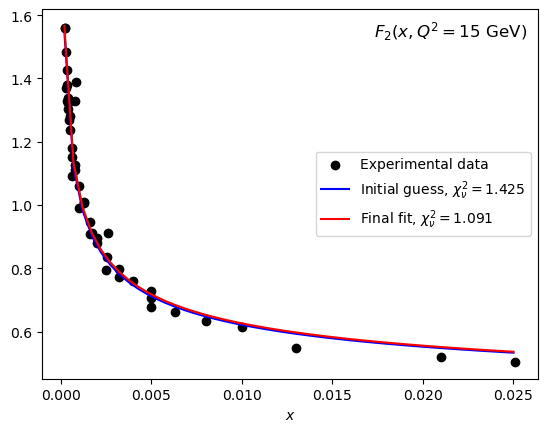

In [71]:
#Plot of the fitted F2 Structure function
for i, D in enumerate(data):
    if i < len(data)-1:
        plt.scatter(D["x"], D["y"], color="black", label='_nolegend_')
    else:
        plt.scatter(D["x"], D["y"], color="black", label='Experimental data')

xvals = np.linspace(2e-4,0.025,50)
plt.plot(xvals, F2(xvals, initParams), color='blue', label="Initial guess, " + r"$\chi^2_{\nu}=$" + f"{initredchi2:.3f}")
plt.plot(xvals, F2(xvals, params), color='red', label="Final fit, " + r"$\chi^2_{\nu}=$" + f"{redchi2:.3f}")
plt.text(0.0173, 1.53, r"$F_2(x,Q^2=15\text{ GeV})$", fontsize=12)
plt.xlabel(r"$x$")
plt.legend()
#plt.savefig("F2 Fit, Q2=15GeV.pdf", format="pdf", bbox_inches='tight')

### Uncertainty estimation via the Hessian matrix method ###

In [72]:
#Compute the full Hessian of the global chi^2 with the final fitted parameters
H = hessian(costfunc1D, None, params.flatten(), fixedParams)
#Solve for the eigenvalues and eigenvectors of the Hessian matrix
# ***Note: Classical methods like the Gram-Schmidt QR decomposition and Gauss-Jordan elimination algorithms are too
#          noisy and numerically unstable for complicated matrices containing a wide range of values like the Hessian
#          of the global chi^2 function. For the sake of time (and my own sanity) I used NumPy's eigh method to 
#          compute the eigenvalues and eigenvectors of H. ***
l, P = np.linalg.eigh(H)
T = 10 #Global chi^2 uncertainty tolerance
#Compute the matrix of parameter uncertainty vectors, \Delta a
M = np.array([T/np.sqrt(np.abs(l))[i] * P[:,i] for i in range(len(l))]).T

#Function for computing the uncertainty in a PDF
#Input: x, 2D array of parameters, index of the row of parameters to evaluate the central f_0 at
def Del_f(x, params, i, fixedParams=[]):
    f_0 = f(x, params[i]) #Compute the fitted PDF
    params = params.flatten()
    diff_plus = [] #List for storing the upper bound of differences
    diff_min = [] #List for storing the lower bound of differences

    fixedIndices = [] #List of the indices of the fixed parameters
    for fix in fixedParams:
        fixedIndices.append(np.ravel_multi_index(fix[0], (numFixedParams, numParams)))

    allIndices = np.arange(0, len(params))
    freeIndices = allIndices[~np.isin(allIndices, fixedIndices)] #List of the indices of the free parameters

    #Calculate the uncertainty in a PDF due to each of the fitted parameters
    for k in range(len(params) - len(fixedParams)):
        Del_a = np.zeros(len(params))
        Del_a[freeIndices] = M[:,k] #Define the kth \Delta_a vector as the kth column vector in M
        f_p = f(x, (params.copy() + Del_a).reshape((numFixedParams, numParams))[i]) #Compute the upper bound of f
        f_m = f(x, (params.copy() - Del_a).reshape((numFixedParams, numParams))[i]) #Compute the lower bound of f
        #Accept the largest upper bound difference as the upper bound of uncertainty 
        diff_p = np.maximum.reduce([f_p - f_0, f_m - f_0, np.zeros_like(f_0)])
        #Accept the largest lower bound difference as the lower bound of uncertainty
        diff_m = np.maximum.reduce([f_0 - f_p, f_0 - f_m, np.zeros_like(f_0)])
        diff_plus.append(diff_p)
        diff_min.append(diff_m)
    
    #Add the uncertainties due to each parameter in quadrature and then take the square root
    diff_p2 = [diff**2 for diff in diff_plus]
    diff_m2 = [diff**2 for diff in diff_min]
    Df_plus = np.sqrt(np.sum(diff_p2, axis=0))
    Df_min = np.sqrt(np.sum(diff_m2, axis=0))
    return Df_plus, -Df_min

#Function for computing xf and its upper/lower bound curves (for f != s)
def xf(x, params, Del_f = 0):
    return x*f(x, params) + Del_f

#Function for computing xs and its upper/lower bound curves
def xs(x, params, fixedParams=[]):
    s_0 = (lambda xval, p: kappa*(f(xval, p[1])+f(xval, p[3]))/2)(x, params)
    Du_plus, Du_min = Del_f(x, params, 1, fixedParams)
    Dd_plus, Dd_min = Del_f(x, params, 3, fixedParams)
    Ds_plus = np.sqrt(Du_plus**2 + Dd_plus**2)
    Ds_min = np.sqrt(Du_min**2 + Dd_min**2)
    lb = x*s_0 - Ds_min
    ub = x*s_0 + Ds_plus

    return x*s_0, lb, ub

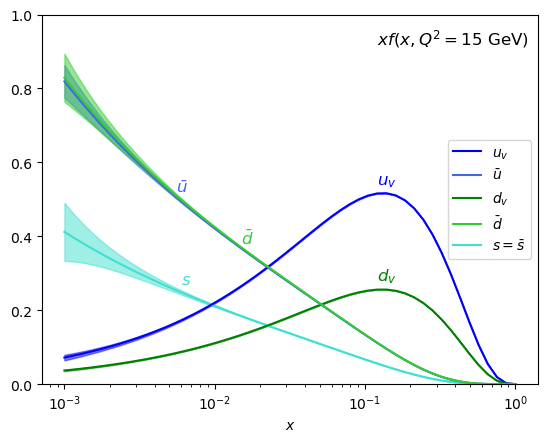

In [73]:
#Plot all of the fitted PDFs (u_v, \bar{u}, d_v, \bar{d}, and s = \bar{s})
x = np.geomspace(1e-3,1)
colors = ["blue", "royalblue", "green", "limegreen"]
labels = [r"$u_v$", r"$\bar{u}$", r"$d_v$", r"$\bar{d}$"]

s, s_lb, s_ub = xs(x, params, fixedParams)
plt.fill_between(x, s_lb, s_ub, color="turquoise", alpha=0.5)
plt.plot(x, s, color="turquoise", label=r"$s=\bar{s}$")

for i in [0,2,1,3]:
    Df_plus, Df_min = Del_f(x, params, i, fixedParams)
    ub = xf(x, params[i], Df_plus)
    lb = xf(x, params[i], Df_min)
    plt.fill_between(x, lb, ub, color=colors[i], alpha=0.5)

for i in [0, 2, 1, 3]:
    plt.plot(x, xf(x, params[i]), color=colors[i], label=labels[i])

plt.semilogx()
plt.ylim((0,1))
plt.xlabel(r"$x$")
plt.text(1.2e-1, 0.92, r"$xf(x,Q^2=15\text{ GeV})$", fontsize=12)

plt.text(1.2e-1, 0.54, r"$u_v$", color=colors[0], fontsize=12)
plt.text(5.5e-3, 0.52, r"$\bar{u}$", color=colors[1], fontsize=12)
plt.text(1.2e-1, 0.28, r"$d_v$", color=colors[2], fontsize=12)
plt.text(1.5e-2, 0.38, r"$\bar{d}$", color=colors[3], fontsize=12)
plt.text(6e-3, 0.27, r"$s$", color="turquoise", fontsize=12)

handles, labels = plt.gca().get_legend_handles_labels()
order = [1, 3, 2, 4, 0] 
plt.legend([handles[i] for i in order], [labels[i] for i in order])
#plt.savefig("PDF Fit, Q2=15GeV.pdf", format="pdf", bbox_inches='tight')